## Why Folktables

Our MNIST and Adult runs showed three patterns:

1. **The harder group pays more for privacy.** On balanced Adult, DP-SGD cost men about 11 points of accuracy and women about 4.
2. **Accuracy hides failure.** DP-SGD missed 95–98% of Adult's high earners, barely better than always answering "≤ \$50K".
3. **Global-Adapt shrinks the gap**: 53 → 13 points on MNIST, 7 → 0.1 on Adult.

Adult is small (about 29,000 people) and from 1994. Do these patterns hold on **larger, modern data**, and how do they change as the training set grows? Esipova et al. did not run Folktables, so this is an **extension, not a reproduction**. Our comparison points are our Adult results and Mangold et al. (2023), who prove that privacy's effect on fairness shrinks with more data, for output perturbation rather than DP-SGD.

**Why it matters:** the US Census Bureau now uses DP to protect the 2020 Census. That is for publishing statistics, not DP-SGD, but it protects the same people as this data. If a privately trained model on such data targeted loans or job ads, a privacy-cost gap would mean one group's errors rise more, even though every record had the same guarantee. A higher false-negative rate means more of that group's qualified people are passed over.

## Setup

- **Data:** ACSIncome (Ding et al., 2021), the American Community Survey replacement for Adult. We use the California 2018 1-Year person file: 195,665 employed adults after Adult's filter (age > 16, income > \$100, hours > 0).
  - **Label:** income > \$50K, not inflation-adjusted. 47% of men and 35% of women clear it, against 32% and 12% on Adult.
  - **Features:** 10: age, class of worker, education, marital status, occupation, birthplace, relationship, hours, sex and race.
- **Preprocessing, as on Adult:** standardize age and hours, one-hot encode the rest (815 inputs), keep sex as an input, and split 80/20 with a seeded shuffle.
- **Experiments** (SPEC §10):
  - **F1, sex on all of California:** balanced like Adult (about 74k per sex in training) and at the natural ratio (53% men).
  - **F2, size sweep:** $n$ = 5k, 10k, 25k, 50k, 100k and all 156,532, at the natural ratio. Subsamples are stratified by sex and drawn from the training split, so the test set is fixed across $n$.
  - **F3, race:** white vs Black, natural ratio. Black Californians are 6.6% of this subset, and other races are excluded.
  - **F4, $\varepsilon$ sweep:** $\varepsilon$ from 0.5 to 8 at $n$ = 25k.
- **Model and training: Adult's presets.** An MLP with two hidden layers of 256 and tanh, 20 epochs, Poisson batches of 256, $\delta = 10^{-6}$. The learning rates, $C$ and the Global-Adapt settings are Adult's.
- **One change: $\varepsilon$ is fixed at 3.41 (Adult's) and $\sigma$ is solved per run** with Opacus's `get_noise_multiplier`. $\sigma$ ranges from 1.71 at 5k to 0.70 on all of California. A fixed $\sigma$ would give a smaller $\varepsilon$ on more data, making sizes incomparable. Global-Adapt uses the same $\sigma$; its private count adds a little $\varepsilon$.
- **Baseline check:** the non-private model is also trained at Global-Adapt's lr 0.2 in every setting, to test how much the privacy costs depend on the baseline.
- **Seeds:** 0–4. Within a seed, all methods share the split and the initial weights, and the subsamples are nested (5k ⊂ 10k ⊂ …).

**Choices where the plan left room** (closest to Adult):

- F2 uses the natural ratio, so its top point is all of California. That is near-balanced (53/47), and F1 shows the two ratios agree.
- Education is one-hot only, as ACSIncome has no `education_num`.
- One-hot encoding runs before balancing, so every variant has the same inputs.

In [1]:
import pandas as pd
from dpdisparity import analysis as A, plots, runner

SOURCE = "rerun"  # Folktables has no dp-testing runs: this loads this repo's results (and trains any that are missing)

In [2]:
#| label: tbl-folk-settings
#| tbl-cap: "Hyperparameters: Adult presets (Esipova et al., App. B), with $\\varepsilon$ fixed at 3.41 and $\\sigma$ solved per run."
A.settings_table("folktables_sex")

,epochs,lr,batch_size,σ,C,Z₀,τ,σ₂,η_Z,δ,target ε
Non-private,20,0.01,256,,,,,,,1e-06,
DP-SGD,20,0.01,256,solved,0.5,,,,,1e-06,3.41
Global-Adapt,20,0.2,256,solved,0.5,50.0,1.0,10.0,0.1,1e-06,3.41


In [3]:
bal = runner.load("folktables_sex", SOURCE, balance=True)  # F1: sexes balanced, as on Adult
nat = runner.load("folktables_sex", SOURCE)                # F1: natural sex ratio (also the largest n in F2)
race = runner.load("folktables_race", SOURCE)              # F3: white vs Black, natural ratio
NS = [5_000, 10_000, 25_000, 50_000, 100_000]
sweep = {n: runner.load("folktables_sex", SOURCE, n_train=n) for n in NS} | {sum(nat[0]["train_counts"]): nat}
adult = runner.load("adult", "legacy")                     # our Adult runs, as reported on the Adult page
SEXES, RACES = ["Male", "Female"], ["White", "Black"]
df_bal, df_nat, df_race = A.to_frame(bal), A.to_frame(nat), A.to_frame(race)
acc_bal = A.summarize(df_bal, "accuracy")

## Phase 1: Non-private baseline

Without privacy, accuracy is about 81% for men and 82% for women, against 81% and 92% on Adult, where "≤ \$50K" was almost always right for women. **Men are only about 1.5 points harder here, against 11.6 on Adult.**

In [4]:
#| label: tbl-folk-base
#| tbl-cap: "Test set per sex (ours, %, mean over 5 seeds; Adult = our dp-testing runs): share > \\$50K, accuracy of always predicting ≤ \\$50K, non-private accuracy."
cols = ["share positive", "constant accuracy", "non-private accuracy"]
pd.concat({"Adult (balanced)": A.base_rates(adult, "adult"), "CA balanced": A.base_rates(bal, "folktables_sex"),
           "CA natural ratio": A.base_rates(nat, "folktables_sex")})[cols]

share positive  constant accuracy  \
Adult (balanced) Male              31.5               68.5   
                 Female            11.6               88.4   
CA balanced      Male              46.7               53.3   
                 Female            34.7               65.3   
CA natural ratio Male              46.4               53.6   
                 Female            35.1               64.9   

                         non-private accuracy  
Adult (balanced) Male                    80.6  
                 Female                  92.2  
CA balanced      Male                    80.9  
                 Female                  82.4  
CA natural ratio Male                    81.1  
                 Female                  82.5

## Phase 2: DP-SGD

On all of California (balanced, $\sigma \approx 0.70$), DP-SGD costs both sexes about the same, a little under 4 points each.

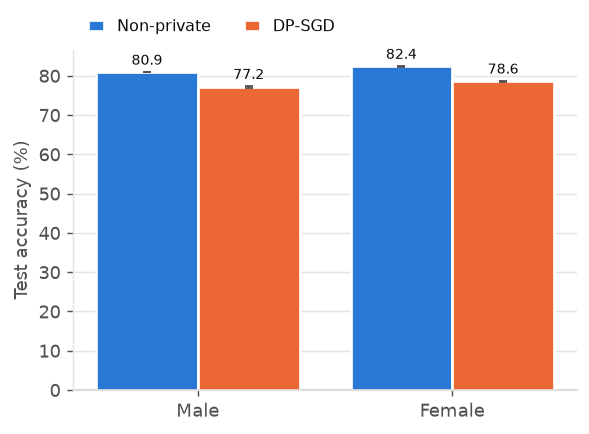

In [5]:
#| label: fig-folk-dpsgd
#| fig-cap: "Test accuracy by sex, CA balanced: non-private vs DP-SGD (ours; mean ± SE)."
plots.group_bars(acc_bal[acc_bal.method != "global_adapt"], SEXES, "Test accuracy (%)", label_groups=SEXES);

## Phase 3: Disparity evaluation

The privacy cost is $\pi_k = A_k(\text{non-private}) - A_k(\text{private})$, paired by seed. The disparity measure is the **privacy-cost gap** $\lvert \pi_{\text{Male}} - \pi_{\text{Female}} \rvert$.

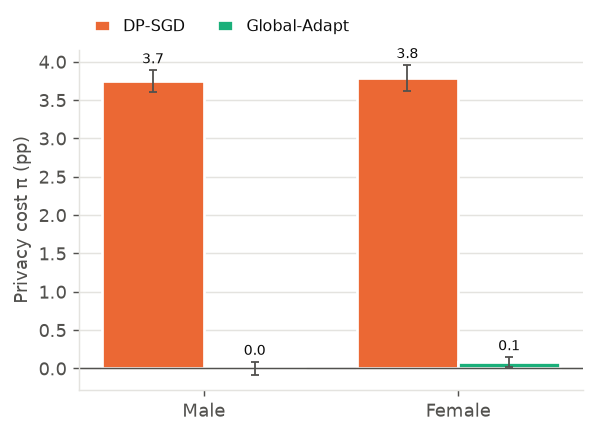

In [6]:
#| label: fig-folk-cost
#| fig-cap: "Privacy cost by sex, CA balanced (ours; pp lost vs non-private, mean ± SE)."
plots.group_bars(A.summarize(A.privacy_costs(df_bal), "pi"), SEXES, "Privacy cost π (pp)", label_groups=SEXES);

### Accuracy still hides something

At this size DP-SGD does **not** fall back to "always ≤ \$50K". Its false-negative rate stays far from 100. But the rise is uneven: DP-SGD misses about 7 more high-earning women per 100 than the non-private model (34 vs 27), and about 3 more men (22 vs 20). Against the stronger lr-0.2 baseline, the figures are about 11 and 4. The accuracy cost is equal, but the extra missed high earners fall more on women.

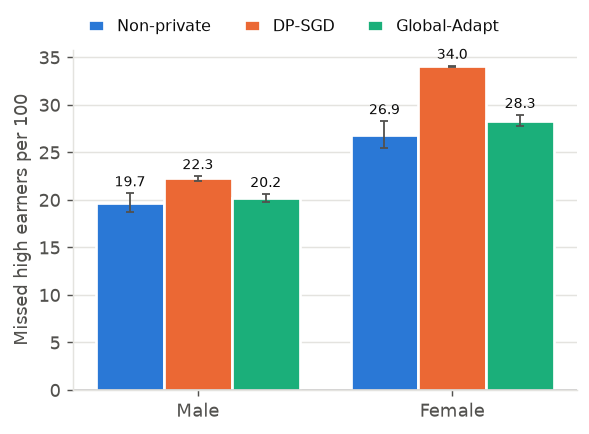

In [7]:
#| label: fig-folk-fnr
#| fig-cap: "False-negative rate by sex, CA balanced: high earners missed per 100 (ours; mean ± SE)."
plots.group_bars(A.summarize(df_bal, "fnr"), SEXES, "Missed high earners per 100", label_groups=SEXES);

## Phase 4: DPSGD-Global-Adapt

Global-Adapt scales every gradient by the same factor $C/Z$ instead of clipping large ones separately, and learns $Z$ privately. It uses no group labels.

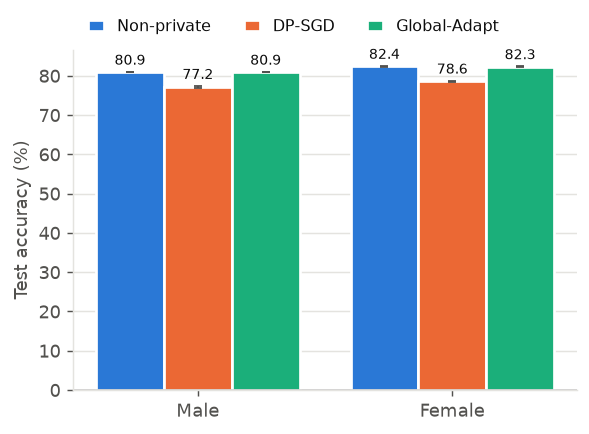

In [8]:
#| label: fig-folk-acc
#| fig-cap: "Test accuracy by sex, CA balanced, all three methods (ours; mean ± SE)."
plots.group_bars(acc_bal, SEXES, "Test accuracy (%)", label_groups=SEXES);

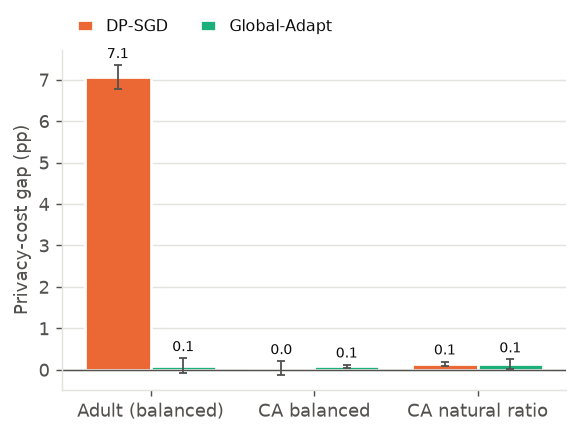

In [9]:
#| label: fig-folk-gap
#| fig-cap: "Privacy-cost gap $\\lvert \\pi_{\\text{Male}} - \\pi_{\\text{Female}} \\rvert$, Adult vs CA at both sex ratios, all at $\\varepsilon \\approx 3.41$ (ours; mean ± SE)."
gap_settings = A.gaps_by_setting({"Adult (balanced)": (adult, "adult"), "CA balanced": (bal, "folktables_sex"),
                                  "CA natural ratio": (nat, "folktables_sex")})
plots.group_bars(gap_settings, list(dict.fromkeys(gap_settings.group)), "Privacy-cost gap (pp)",
                 label_groups=set(gap_settings.group));

Global-Adapt brings both sexes back to within about 0.1 points of the non-private accuracy, and their false-negative rates to within about 1.5 points. Against a non-private model at Global-Adapt's own lr 0.2, it falls about 0.5–0.8 points short on all of California (natural ratio; see the baseline check).

**There is no gap left to reduce:** DP-SGD's gap is already 0.05 ± 0.16 (balanced) and 0.14 ± 0.06 (natural), and Global-Adapt's is 0.08 ± 0.05 and 0.13 ± 0.12. On Adult it shrank 7 points to 0.1. As on Adult, Global-Adapt uses lr 0.2 against DP-SGD's 0.01.

## Comparison with Adult

With no published Folktables target, we compare with **our** Adult runs (the dp-testing runs on the [Adult page](02_adult_subgroup_disparity.ipynb)). $\varepsilon$ is about 3.41 throughout, so gap sizes are comparable, unlike between MNIST and Adult.

In [10]:
#| label: tbl-folk-vs-adult
#| tbl-cap: "Key numbers (ours, mean over 5 seeds, %): Adult vs CA balanced vs CA natural ratio."
pd.DataFrame({"Adult (balanced)": A.headline(adult, "adult"), "CA balanced": A.headline(bal, "folktables_sex"),
              "CA natural ratio": A.headline(nat, "folktables_sex")})

,Adult (balanced),CA balanced,CA natural ratio
Non-private: Acc Male,80.57,80.94,81.09
Non-private: Acc Female,92.18,82.43,82.47
DP-SGD: Acc Male,69.86,77.20,77.29
DP-SGD: Acc Female,88.54,78.64,78.53
Global-Adapt: Acc Male,80.57,80.94,81.09
Global-Adapt: Acc Female,92.29,82.35,82.34
DP-SGD: gap,7.07,0.05,0.14
Global-Adapt: gap,0.10,0.08,0.13
DP-SGD: ε,3.41,3.40,3.41
Global-Adapt: ε,3.42,3.41,3.41


**Adult's result does not carry over to all of California:** the gap is 7 points there and about 0.1 here, at the same $\varepsilon$. California has about 6× more training data and barely-harder men; the size sweep separates the two.

## Size sweep: does more data make privacy's cost fairer?

The centrepiece: only the training-set size changes. 25k is about Adult's training size.

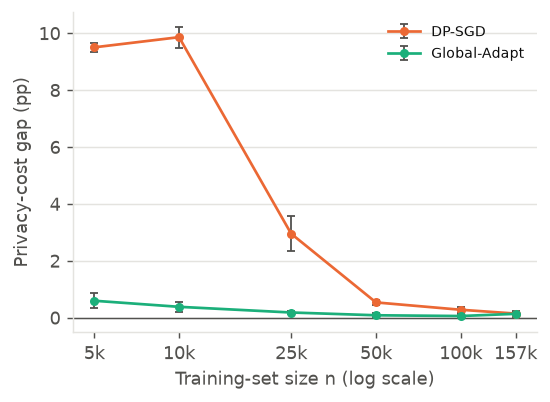

In [11]:
#| label: fig-folk-sweep
#| fig-cap: "Privacy-cost gap $\\lvert \\pi_{\\text{Male}} - \\pi_{\\text{Female}} \\rvert$ vs training-set size, CA natural ratio, $\\varepsilon = 3.41$, same test set at every $n$ (ours; mean ± SE)."
sw = A.size_sweep(sweep, "folktables_sex")
plots.vs_n(sw["gap"], "Privacy-cost gap (pp)", figsize=(4.6, 3.2));  # same size as the MNIST/Adult gap charts (home page)

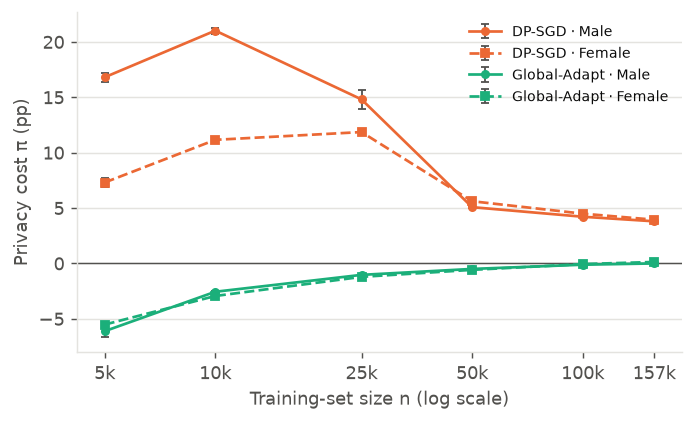

In [12]:
#| label: fig-folk-sweep-pi
#| fig-cap: "Privacy cost per sex vs training-set size, against the lr-0.01 non-private baseline (ours; mean ± SE). Solid: men; dashed: women. For Global-Adapt's negative values, see the baseline check."
plots.vs_n(sw["pi"], "Privacy cost π (pp)");

In [13]:
#| label: tbl-folk-sweep
#| tbl-cap: "Size sweep (ours, mean ± SE, pp): gap per method, solved $\\sigma$ and achieved $\\varepsilon$."
info_n = pd.concat({n: A.run_info(r) for n, r in sweep.items()}, names=["n_train", "method"])
gap_n = sw["gap"].assign(method=sw["gap"].method.map(A.METHOD_LABELS)).set_index(["n_train", "method"])
out = gap_n[["mean", "se"]].round(2).join(info_n[["sigma", "epsilon"]])
out.rename(columns={"mean": "gap", "se": "SE", "sigma": "σ (solved)", "epsilon": "ε (achieved)"}).rename_axis(["n", "Method"])

gap    SE σ (solved) ε (achieved)
n      Method                                          
5000   DP-SGD        9.50  0.16      1.714        3.408
       Global-Adapt  0.59  0.27      1.714        3.446
10000  DP-SGD        9.86  0.37      1.309        3.407
       Global-Adapt  0.38  0.17      1.309        3.426
25000  DP-SGD        2.95  0.62      0.983        3.409
       Global-Adapt  0.18  0.07      0.983        3.416
50000  DP-SGD        0.54  0.09      0.837        3.404
       Global-Adapt  0.08  0.07      0.837        3.407
100000 DP-SGD        0.28  0.10      0.742        3.405
       Global-Adapt  0.06  0.07      0.742        3.406
156532 DP-SGD        0.14  0.06      0.696        3.407
       Global-Adapt  0.13  0.12      0.696        3.408

**DP-SGD's gap shrinks sharply with $n$, as a threshold rather than a smooth decline.** It is about 10 points up to 10k, falls about 20-fold by 50k, and stays under 1 beyond that.

That fits Mangold et al.'s result that the gap shrinks with $n$, a bound for a different method. The shape, though, follows when DP-SGD stops falling back to the constant answer (next section), not a gradual $\sqrt{p}/n$ decay.

**Size and training length move together.** At 20 epochs, $n$ = 5k gets 400 steps and all of California 12,240. DP-SGD's cost here is almost all clipping ($\varepsilon$ sweep below), and small clipped steps need many steps. So part of the decline may be "more steps", not "more data".

- **At Adult's size (25k):** the gap is 3.0 ± 0.6 against Adult's 7.1 ± 0.3. Men pay more on both. We read the difference as men being far harder than women on Adult.
- **At large $n$:** from 50k on, women pay slightly more, by 0.1–0.5 points of accuracy and more in false negatives.
- **Global-Adapt: at most 0.6 points at every $n$.** At small $n$ it reduces DP-SGD's 10-point gap to under 1.
  - Its $\pi$ is negative there: it beats the non-private model by up to 6 points at 5k.
  - That is not privacy helping. The non-private model (400 steps, lr 0.01) is undertrained, and Global-Adapt's steps are 20× larger. Against a non-private model at lr 0.2, Global-Adapt's $\pi$ is +2.7 / +2.6 at 5k (baseline check below).

## Race: when the harder group is also the smaller one

Black Californians are the smaller group (about 6,900 in training) and the harder one (about 2 points lower non-private accuracy). On MNIST, where the hard group was rare, Global-Adapt only partly closed the gap. How much does it recover here?

In [14]:
#| label: tbl-folk-race-counts
#| tbl-cap: "White and Black Californians (seed 0 counts; share > \\$50K is the 5-seed test mean)."
pd.DataFrame({"train": race[0]["train_counts"], "test": [race[0]["evaluation"]["groups"][g]["n"] for g in RACES],
              "share > $50K (%)": A.base_rates(race, "folktables_race")["share positive"].to_list()}, index=RACES)

,train,test,share > $50K (%)
White,96791,24215,44.2
Black,6860,1697,34.5


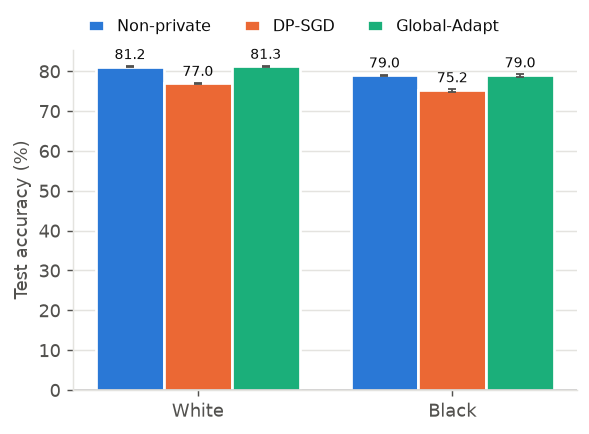

In [15]:
#| label: fig-folk-race-acc
#| fig-cap: "Test accuracy, white vs Black, all three methods (ours; mean ± SE)."
plots.group_bars(A.summarize(df_race, "accuracy"), RACES, "Test accuracy (%)", label_groups=RACES);

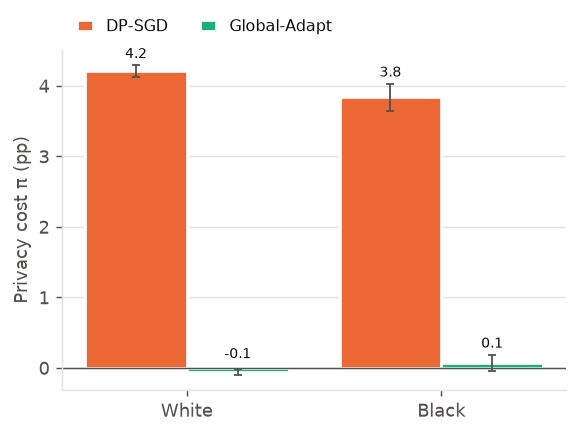

In [16]:
#| label: fig-folk-race-cost
#| fig-cap: "Privacy cost, white vs Black (ours; mean ± SE)."
plots.group_bars(A.summarize(A.privacy_costs(df_race), "pi"), RACES, "Privacy cost π (pp)", label_groups=RACES);

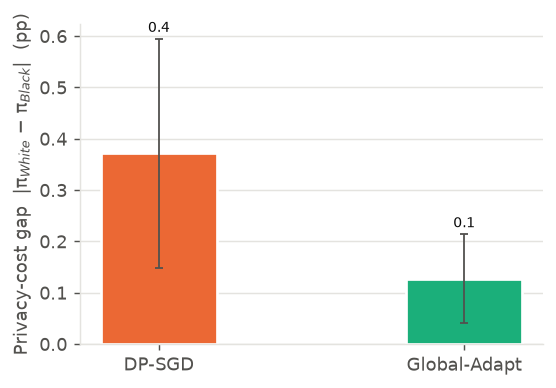

In [17]:
#| label: fig-folk-race-gap
#| fig-cap: "Privacy-cost gap $\\lvert \\pi_{\\text{White}} - \\pi_{\\text{Black}} \\rvert$ (ours; mean ± SE; no published target)."
plots.gap_bars(A.gaps(df_race, "folktables_race"), "folktables_race");

**At full size both groups pay about the same:** about 4.2 points for white and 3.8 for Black Californians. The gap is 0.4 ± 0.2 (0.5 ± 0.2 against the lr-0.2 baseline), and in each case one seed in five has the opposite sign. Global-Adapt brings both groups back to the lr-0.01 non-private accuracy (gap 0.1 ± 0.1). Against the lr-0.2 baseline, both groups are about 0.9 points short.

So there is no meaningful gap to recover at this size, and the open question stays open. The test set has only about 1,700 Black Californians, so a few tenths of a point is within noise.

**The error type does shift.** Under DP-SGD:

- The share of Black Californians predicted over \$50K rises from 31% to 37%, toward the white rate of 45%.
- Their false-positive rate rises 13 → 21, against 17 → 22 for white Californians.
- Their false-negative rate dips (36 → 32).

This is *consistent with* DP-SGD learning less group-specific signal for a small group (our observation).

## Testing our Adult observation: does DP-SGD fall back to "always ≤ \$50K"?

On Adult (ours, not published), DP-SGD's accuracy was close to always predicting "≤ \$50K". Each group's $\pi$ was close to its **headroom**, meaning how far its non-private model sat above that constant. If that holds, the gap is just the difference in headroom. Here the fallback is costlier, because the base rates are higher.

In [18]:
#| label: tbl-folk-baserate
#| tbl-cap: "Does DP-SGD fall back to always predicting ≤ \\$50K? (ours, %, mean over 5 seeds). Headroom = non-private − constant accuracy. A fallback shows as FNR ≈ 100 and $\\pi$ ≈ headroom."
pd.concat({"Adult (balanced)": A.base_rates(adult, "adult"),
           **{f"CA n = {n:,}": A.base_rates(r, "folktables_sex") for n, r in sweep.items()},
           "CA balanced": A.base_rates(bal, "folktables_sex"), "CA race": A.base_rates(race, "folktables_race")})

share positive  constant accuracy  \
Adult (balanced) Male              31.5               68.5   
                 Female            11.6               88.4   
CA n = 5,000     Male              46.4               53.6   
                 Female            35.1               64.9   
CA n = 10,000    Male              46.4               53.6   
                 Female            35.1               64.9   
CA n = 25,000    Male              46.4               53.6   
                 Female            35.1               64.9   
CA n = 50,000    Male              46.4               53.6   
                 Female            35.1               64.9   
CA n = 100,000   Male              46.4               53.6   
                 Female            35.1               64.9   
CA n = 156,532   Male              46.4               53.6   
                 Female            35.1               64.9   
CA balanced      Male              46.7               53.3   
                 Female            34.7               65.3   
CA race          White             44.2               55.8   
                 Black             34.5               65.5   

                         non-private accuracy  headroom  DP-SGD accuracy  \
Adult (balanced) Male                    80.6      12.1             69.9   
                 Female                  92.2       3.8             88.5   
CA n = 5,000     Male                    70.5      16.9             53.7   
                 Female                  72.2       7.3             64.9   
CA n = 10,000    Male                    75.2      21.6             54.2   
                 Female                  76.1      11.2             64.9   
CA n = 25,000    Male                    78.0      24.4             63.2   
                 Female                  79.2      14.4             67.4   
CA n = 50,000    Male                    79.5      25.9             74.4   
                 Female                  80.8      16.0             75.2   
CA n = 100,000   Male                    80.7      27.1             76.5   
                 Female                  82.0      17.2             77.5   
CA n = 156,532   Male                    81.1      27.5             77.3   
                 Female                  82.5      17.6             78.5   
CA balanced      Male                    80.9      27.7             77.2   
                 Female                  82.4      17.2             78.6   
CA race          White                   81.2      25.4             77.0   
                 Black                   79.0      13.5             75.2   

                         DP-SGD FNR  DP-SGD π  
Adult (balanced) Male          94.9      10.7  
                 Female        98.4       3.6  
CA n = 5,000     Male          99.6      16.8  
                 Female        99.8       7.3  
CA n = 10,000    Male          97.9      21.0  
                 Female        99.2      11.2  
CA n = 25,000    Male          71.5      14.8  
                 Female        87.5      11.9  
CA n = 50,000    Male          26.0       5.1  
                 Female        42.3       5.6  
CA n = 100,000   Male          21.8       4.2  
                 Female        34.9       4.5  
CA n = 156,532   Male          22.0       3.8  
                 Female        33.4       3.9  
CA balanced      Male          22.3       3.7  
                 Female        34.0       3.8  
CA race          White         23.8       4.2  
                 Black         32.3       3.8

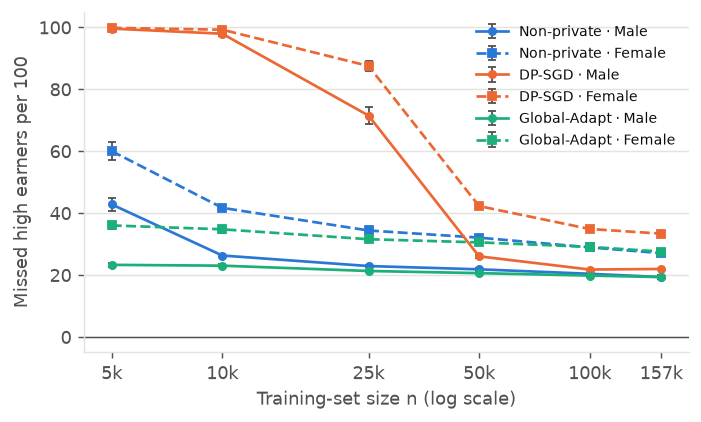

In [19]:
#| label: fig-folk-sweep-fnr
#| fig-cap: "False-negative rate per sex vs training-set size (ours; mean ± SE). Solid: men; dashed: women."
plots.vs_n(sw["fnr"], "Missed high earners per 100");

**At 5k and 10k it holds almost exactly:** DP-SGD misses 98–100% of high earners, and $\pi$ matches the headroom to within 0.6 points.

| | Men: headroom / $\pi$ | Women: headroom / $\pi$ |
|---|---|---|
| 5k | 16.9 / 16.8 | 7.3 / 7.3 |
| 10k | 21.6 / 21.0 | 11.2 / 11.2 |
| Adult | 12 / 10.7 | 4 / 3.7 |

Once DP-SGD's accuracy equals the constant's, $\pi$ equals the headroom by definition, under any baseline: 25.8 / 25.7 for men at 5k against the lr-0.2 baseline. **The finding is the fallback itself.**

**From 25k on it breaks down.**

- At 25k, DP-SGD still misses 72% of high-earning men and 88% of women, but $\pi$ is below the headroom.
- From 50k on, its false-negative rates are 1–10 points above non-private, and $\pi$ is at most a fifth of the headroom.
- The size sweep's gap collapses at the same $n$.

So the large gaps arise when DP-SGD learns nothing beyond the majority answer. The group whose non-private model had learned more loses more. The $\varepsilon$ sweep shows that clipping, not noise, drives this fallback, which fits Esipova et al. Whether clipping hurts through the update's *direction* (their gradient misalignment) or its *size* needs the mechanism experiments.

## Privacy budget sweep: does stronger privacy widen the gap?

Sanyal et al. (2022) predict that the gap grows as privacy tightens, then shrinks once everyone does badly. We vary $\varepsilon$ from 0.5 to 8 ($\sigma \approx 4.1$ to 0.7) at $n$ = 25k, where the size sweep changes fastest.

In [20]:
EPS = [0.5, 1, 2, 3.41, 8]
eps_runs = {e: runner.load("folktables_sex", SOURCE, n_train=25_000, target_epsilon=e) for e in EPS}
es = A.size_sweep(eps_runs, "folktables_sex", key="epsilon")

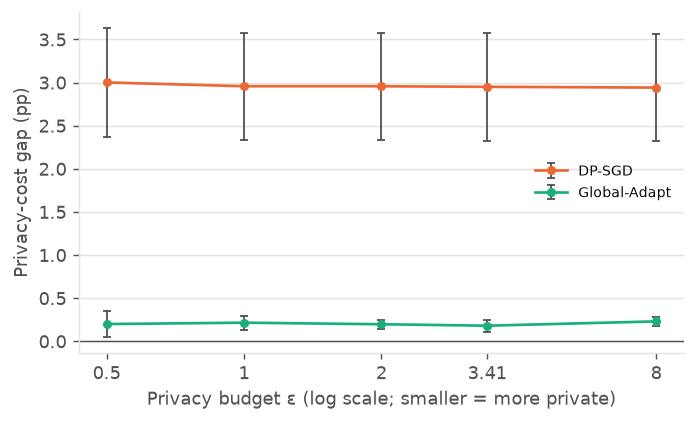

In [21]:
#| label: fig-folk-eps
#| fig-cap: "Privacy-cost gap vs $\\varepsilon$ at $n$ = 25,000, CA natural ratio (ours; mean ± SE). Smaller $\\varepsilon$ = stronger privacy."
plots.vs_n(es["gap"], "Privacy-cost gap (pp)", x="epsilon", xlabel="Privacy budget ε (log scale; smaller = more private)");

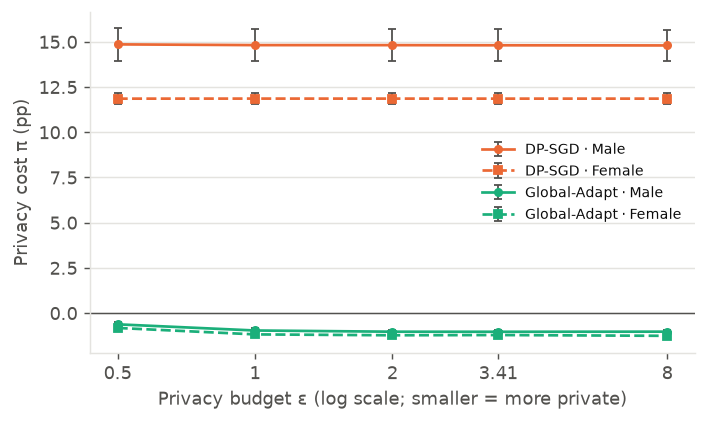

In [22]:
#| label: fig-folk-eps-pi
#| fig-cap: "Privacy cost per sex vs $\\varepsilon$ at $n$ = 25,000, against the lr-0.01 baseline (ours; mean ± SE). Solid: men; dashed: women. Global-Adapt's values below 0: see the baseline check."
plots.vs_n(es["pi"], "Privacy cost π (pp)", x="epsilon", xlabel="Privacy budget ε (log scale; smaller = more private)");

In [23]:
#| label: tbl-folk-eps
#| tbl-cap: "$\\varepsilon$ sweep at $n$ = 25,000 (ours, mean ± SE, pp): gap, solved $\\sigma$ and achieved $\\varepsilon$."
info_e = pd.concat({e: A.run_info(r) for e, r in eps_runs.items()}, names=["target ε", "method"])
gap_e = es["gap"].assign(method=es["gap"].method.map(A.METHOD_LABELS)).rename(columns={"epsilon": "target ε"})
out = gap_e.set_index(["target ε", "method"])[["mean", "se"]].round(2).join(info_e[["sigma", "epsilon"]])
out.rename(columns={"mean": "gap", "se": "SE", "sigma": "σ (solved)", "epsilon": "ε (achieved)"}).rename_axis(["target ε", "Method"])

gap    SE σ (solved) ε (achieved)
target ε Method                                          
0.50     DP-SGD        3.00  0.63      4.062        0.496
         Global-Adapt  0.20  0.15      4.062        0.535
1.00     DP-SGD        2.96  0.62      2.227        0.992
         Global-Adapt  0.22  0.08      2.227        1.014
2.00     DP-SGD        2.96  0.62      1.323        1.996
         Global-Adapt  0.20  0.05      1.323        2.008
3.41     DP-SGD        2.95  0.62      0.983        3.409
         Global-Adapt  0.18  0.07      0.983        3.416
8.00     DP-SGD        2.94  0.62      0.704        7.991
         Global-Adapt  0.23  0.05      0.704        7.994

**The gap does not move.** DP-SGD's gap is 2.9–3.0 at every $\varepsilon$, and each sex's $\pi$ changes by under 0.1, although $\sigma$ varies almost 6-fold. Global-Adapt stays at about 0.2. There is no two-phase pattern in this range; much stronger privacy would eventually let the noise dominate.

**Diagnostic, seed 0 only, outside the stored sweep:** DP-SGD with $\sigma = 0$, which is clipping only with no privacy.

| Seed 0, ours, accuracy men / women | $\sigma = 0$ (clip only) | $\sigma = 4.06$ ($\varepsilon \approx 0.5$) | $\sigma = 20$ ($\varepsilon \approx 0.16$) |
|---|---|---|---|
| $n$ = 25k | 62.1 / 67.1 | 61.8 / 67.0 | 61.5 / 66.8 |
| All of California | 77.04 / 78.23 | 77.03 / 78.22 at $\varepsilon = 3.41$ | – |

**So nearly all of DP-SGD's cost and gap here comes from clipping, not noise.** With $C = 0.5$ and lr 0.01, clipped steps are small, and 20 epochs get the model only partway. The noise averages out; the clipping is systematic.

Global-Adapt's $\pi$ sits just below 0 at every $\varepsilon$ for the same reason as at small $n$. Against the lr-0.2 baseline it is about +1.3 to +1.8.

This is *consistent with* Esipova et al., and a caution for reading the size sweep. Adult uses the same settings, so this may hold there too; we have not checked.

## Checking the baseline: non-private at Global-Adapt's learning rate

Every privacy cost is measured against a non-private model. Ours uses Adult's preset, lr 0.01, which is undertrained at small $n$: at 5k it gets 400 steps. Global-Adapt, at lr 0.2, beats it, and that produces the negative $\pi$ in the size-sweep and $\varepsilon$ figures.

To check how much the conclusions depend on this, we also trained the non-private model at Global-Adapt's lr 0.2, for every setting (5 seeds each), and recomputed $\pi$ and the gaps against it. The lr-0.01 baseline stays primary on this page, for comparability with Adult and the paper.

In [24]:
#| label: tbl-folk-baseline
#| tbl-cap: "Privacy-cost gaps and Global-Adapt's $\\pi$ against two non-private baselines: lr 0.01 (preset, used elsewhere on this page) and lr 0.2 (Global-Adapt's). Ours; mean ± SE over 5 seeds, pp; pairs are first / second group."
CASES = {**{f"n = {n:,}": ("folktables_sex", {"n_train": n}) for n in NS}, "all CA, natural": ("folktables_sex", {}),
         "all CA, balanced": ("folktables_sex", {"balance": True}), "race": ("folktables_race", {})}
pd.concat({label: A.setting_summary({k: (runner.load(ds, SOURCE, baseline_lr=lr, **kw), ds) for k, (ds, kw) in CASES.items()})
           for label, lr in {"lr 0.01 (preset)": None, "lr 0.2 (matched)": 0.2}.items()}, names=["non-private baseline", "setting"])

groups non-private acc  \
non-private baseline setting                                           
lr 0.01 (preset)     n = 5,000         Male / Female     70.5 / 72.2   
                     n = 10,000        Male / Female     75.2 / 76.1   
                     n = 25,000        Male / Female     78.0 / 79.2   
                     n = 50,000        Male / Female     79.5 / 80.8   
                     n = 100,000       Male / Female     80.7 / 82.0   
                     all CA, natural   Male / Female     81.1 / 82.5   
                     all CA, balanced  Male / Female     80.9 / 82.4   
                     race              White / Black     81.2 / 79.0   
lr 0.2 (matched)     n = 5,000         Male / Female     79.4 / 80.3   
                     n = 10,000        Male / Female     77.7 / 78.4   
                     n = 25,000        Male / Female     80.5 / 81.8   
                     n = 50,000        Male / Female     80.6 / 81.6   
                     n = 100,000       Male / Female     81.7 / 83.1   
                     all CA, natural   Male / Female     81.6 / 83.2   
                     all CA, balanced  Male / Female     80.8 / 81.7   
                     race              White / Black     82.1 / 79.8   

                                         DP-SGD gap Global-Adapt gap  \
non-private baseline setting                                           
lr 0.01 (preset)     n = 5,000          9.50 ± 0.16      0.59 ± 0.27   
                     n = 10,000         9.86 ± 0.37      0.38 ± 0.17   
                     n = 25,000         2.95 ± 0.62      0.18 ± 0.07   
                     n = 50,000         0.54 ± 0.09      0.08 ± 0.07   
                     n = 100,000        0.28 ± 0.10      0.06 ± 0.07   
                     all CA, natural    0.14 ± 0.06      0.13 ± 0.12   
                     all CA, balanced   0.05 ± 0.16      0.08 ± 0.05   
                     race               0.37 ± 0.22      0.13 ± 0.09   
lr 0.2 (matched)     n = 5,000         10.22 ± 0.32      0.13 ± 0.15   
                     n = 10,000        10.00 ± 0.26      0.53 ± 0.33   
                     n = 25,000         2.86 ± 0.64      0.09 ± 0.19   
                     n = 50,000         0.29 ± 0.42      0.33 ± 0.42   
                     n = 100,000        0.36 ± 0.18      0.14 ± 0.17   
                     all CA, natural    0.37 ± 0.10      0.36 ± 0.19   
                     all CA, balanced   0.59 ± 0.71      0.56 ± 0.56   
                     race               0.49 ± 0.19      0.01 ± 0.33   

                                      Global-Adapt π  
non-private baseline setting                          
lr 0.01 (preset)     n = 5,000           -6.1 / -5.5  
                     n = 10,000          -2.6 / -2.9  
                     n = 25,000          -1.0 / -1.2  
                     n = 50,000          -0.5 / -0.6  
                     n = 100,000         -0.1 / -0.1  
                     all CA, natural       0.0 / 0.1  
                     all CA, balanced      0.0 / 0.1  
                     race                 -0.1 / 0.1  
lr 0.2 (matched)     n = 5,000             2.7 / 2.6  
                     n = 10,000          -0.1 / -0.7  
                     n = 25,000            1.4 / 1.3  
                     n = 50,000            0.5 / 0.2  
                     n = 100,000           0.8 / 1.0  
                     all CA, natural       0.5 / 0.8  
                     all CA, balanced    -0.1 / -0.7  
                     race                  0.9 / 0.9

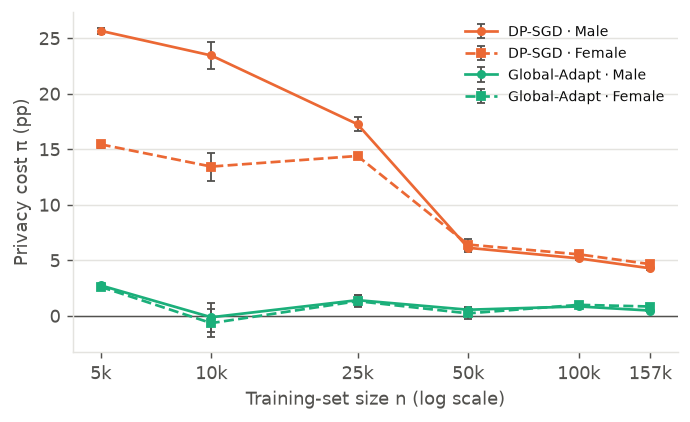

In [25]:
#| label: fig-folk-baseline-pi
#| fig-cap: "Privacy cost per sex vs training-set size, measured against the lr-0.2 non-private baseline (ours; mean ± SE). Compare with the size-sweep figure above, which uses the lr-0.01 baseline. Solid: men; dashed: women."
sweep_m = {n: runner.load("folktables_sex", SOURCE, n_train=n, baseline_lr=0.2) for n in NS} | {max(sweep): runner.load("folktables_sex", SOURCE, baseline_lr=0.2)}
plots.vs_n(A.size_sweep(sweep_m, "folktables_sex")["pi"], "Privacy cost π (pp)");

**The gap conclusions hold under either baseline. Global-Adapt's negative costs do not.**

- **lr 0.2 gives a stronger but noisier baseline.**
  - It is about 9 points more accurate at 5k (79.4 / 80.3 vs 70.5 / 72.2), about 0.5–0.7 points more accurate on all of California (natural ratio), and always reaches a lower training loss.
  - Without learning-rate decay, 3 of its 40 runs end at a poor point (10k seeds 0 and 3, balanced seed 4). That inflates those rows' SEs.
- **DP-SGD's gap keeps its shape.** From 5k to all of California it is 10.2, 10.0, 2.9, 0.3, 0.4, 0.4 (against 9.5, 9.9, 3.0, 0.5, 0.3, 0.1). At full size it is 0.4 ± 0.1 rather than 0.1: still under 1 point, with women paying slightly more.
- **Global-Adapt's gap stays at or below about 0.6** under both baselines.
- **Global-Adapt's $\pi$ turns positive.** It is +2.7 / +2.6 at 5k (instead of −6.1 / −5.5), about +1.4 at 25k, and +0.5 / +0.8 on all of California.
  - So the negative costs came from the weak baseline. Global-Adapt recovers most, but not all, of a well-trained non-private model's accuracy.
  - At 10k and on balanced CA it stays slightly negative, because of the noisy baseline runs.
- **DP-SGD's costs grow** (25.7 / 15.4 at 5k, 4.3 / 4.6 on all of California). The false-negative finding gets stronger: on balanced CA, DP-SGD misses about 11 more high-earning women per 100 than the lr-0.2 model, and about 4 more men.
- **Race:** DP-SGD's gap is 0.5 ± 0.2 (one seed in five has the opposite sign), and Global-Adapt's is 0.0 ± 0.3.

**Still unresolved:** DP-SGD (lr 0.01) and Global-Adapt (lr 0.2) still differ in learning rate, and the private models' step count still grows with $n$.

## Run details

In [26]:
#| label: tbl-folk-runs
#| tbl-cap: "Achieved $\\varepsilon$ (RDP, $\\delta = 10^{-6}$), solved $\\sigma$ and final $Z$, means over seeds (ours)."
pd.concat({"CA balanced": A.run_info(bal), "CA natural ratio": A.run_info(nat), "CA race": A.run_info(race)})

seeds epsilon  delta  sigma final_Z source
                 method                                                 
CA balanced      Non-private      5       –      –      –       –  rerun
                 DP-SGD           5   3.405  1e-06  0.701       –  rerun
                 Global-Adapt     5   3.406  1e-06  0.701   14.94  rerun
CA natural ratio Non-private      5       –      –      –       –  rerun
                 DP-SGD           5   3.407  1e-06  0.696       –  rerun
                 Global-Adapt     5   3.408  1e-06  0.696   14.33  rerun
CA race          Non-private      5       –      –      –       –  rerun
                 DP-SGD           5   3.403  1e-06  0.738       –  rerun
                 Global-Adapt     5   3.404  1e-06  0.738   12.59  rerun

In [27]:
nat[-1]["provenance"]

{'python': '3.12.15',
 'torch': '2.11.0+cu128',
 'opacus': '1.6.0',
 'cuda': '12.8',
 'device': 'cuda',
 'gpu': 'NVIDIA GeForce RTX 5060 Ti',
 'git_sha': 'bb18e5160f736124572f1462428d0d629a08c86b',
 'timestamp': '2026-11-12T09:52:26+00:00',
 'elapsed_s': 95.7}

## Takeaways

All numbers are ours, at $\varepsilon = 3.41$.

- **The gap shrinks with size:** about 10 points at 5–10k, under 1 from 50k on, and 0.1 on all of California (0.4 against a better-trained non-private baseline). This is *consistent with* Mangold et al., though training length also grows with $n$.
- **Large gaps mean DP-SGD falls back to the majority answer** at small $n$, as our Adult observation suggested. $\pi$ then equals each group's headroom, so the gap is the difference in headroom.
- **Clipping, not noise, carries the cost:** the gap is flat for $\varepsilon$ from 0.5 to 8. This is *consistent with* Esipova et al.
- **Adult's 7-point gap does not carry over at full size:** it is 3.0 at Adult's size here, where men are barely harder.
- **Global-Adapt keeps the gap at 0.6 or less at every $n$,** under both baselines, and recovers most of both groups' accuracy. Its negative costs at small $n$ came from the undertrained lr-0.01 baseline.
- **Race:** at full size both groups pay about the same, but Black Californians get more false positives.
- **Accuracy hides the error type:** DP-SGD misses about 7 more high-earning women per 100 against 3 more men.

## Caveats

- **Extension, not a reproduction:** there is no published target, and every number is ours.
- **Training length is tied to $n$** (400 steps at 5k, 12,240 on all of California).
  - The preset (lr 0.01) non-private baseline is undertrained at small $n$, with false-negative rates of 43% (men) and 60% (women) at 5k. A matched lr-0.2 baseline leaves the gap conclusions unchanged (baseline check), but it is itself noisy in 3 of 40 runs.
  - Because the cost is clipping-driven, part of the size trend may be training length. A fixed-steps sweep would separate them.
- **The private methods' learning rates still differ** (Global-Adapt 0.2, DP-SGD 0.01), and that alone could explain much of Global-Adapt's advantage over DP-SGD. The baseline check matches only the non-private model.
- **The clipping-only diagnostic is one seed.** The $\varepsilon$ sweep is five.
- **Global-Adapt's count adds $\varepsilon$:** 3.45 at 5k, 0.535 at target 0.5, and under +0.01 on all of California.
- **One state and year** (CA 2018). The **\$50K threshold** makes the "≤ \$50K" fallback costlier than on Adult.
- **These outcome metrics are consistent with gradient misalignment but do not test it.**